In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
from google.colab import files
import io

uploaded = files.upload()

csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError(
        "No CSV file uploaded. Please upload the extracted emails.csv file."
    )

df = pd.read_csv(io.BytesIO(uploaded[csv_files[0]]))

print("Dataset loaded successfully!")
print("File:", csv_files[0])
print("Dataset shape:", df.shape)

Saving emails.csv to emails.csv
Dataset loaded successfully!
File: emails.csv
Dataset shape: (5172, 3002)


In [3]:
print("First five rows:")
display(df.head())

print("\nDataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in the dataset:", df.isnull().sum().sum())

print("\nStatistical summary:")
display(df.describe())

First five rows:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0



Dataset dimensions:
(5172, 3002)

Column names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'othe

,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
count,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,...,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000
mean,6.640565,6.188128,5.143852,3.075599,3.124710,2.627030,55.517401,2.466551,2.024362,10.600155,...,0.005027,0.012568,0.010634,0.098028,0.004254,0.006574,0.004060,0.914733,0.006961,0.290023
std,11.745009,9.534576,14.101142,6.045970,4.680522,6.229845,87.574172,4.314444,6.967878,19.281892,...,0.105788,0.199682,0.116693,0.569532,0.096252,0.138908,0.072145,2.780203,0.098086,0.453817
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,12.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,1.000000,1.000000,2.000000,1.000000,28.000000,1.000000,0.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,7.000000,4.000000,3.000000,4.000000,2.000000,62.250000,3.000000,1.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,210.000000,132.000000,344.000000,89.000000,47.000000,77.000000,1898.000000,70.000000,167.000000,223.000000,...,4.000000,7.000000,2.000000,12.000000,3.000000,4.000000,3.000000,114.000000,4.000000,1.000000


In [4]:
# Remove extra spaces from column names
df.columns = df.columns.astype(str).str.strip()

# Identify the target column
normalized_columns = {
    str(col).strip().lower().replace(" ", "_"): col
    for col in df.columns
}

target_candidates = [
    "prediction", "label", "spam", "target", "class", "is_spam"
]

target_col = next(
    (
        normalized_columns[name]
        for name in target_candidates
        if name in normalized_columns
    ),
    df.columns[-1]
)

print("Target column identified:", target_col)

# Remove rows with missing target values
df = df.dropna(subset=[target_col]).copy()

# Convert target to numeric labels
y_numeric = pd.to_numeric(df[target_col], errors="coerce")

valid_rows = y_numeric.notna()
df = df.loc[valid_rows].copy()
y = y_numeric.loc[valid_rows].astype(int)

# Separate input features and target
X = df.drop(columns=[target_col]).copy()

# Identify and remove email ID columns
id_columns = []

for col in X.columns:
    cleaned_name = "".join(
        char for char in str(col).lower()
        if char.isalnum()
    )

    if cleaned_name in {"emailno", "emailid", "id", "unnamed0"}:
        id_columns.append(col)

X = X.drop(columns=id_columns, errors="ignore")

# Convert remaining features to numeric values
X = X.apply(pd.to_numeric, errors="coerce")

# Remove columns that contain no usable numeric values
X = X.dropna(axis=1, how="all")

# Replace remaining missing feature values with zero
X = X.fillna(0)

# Reduce memory usage
X = X.astype(np.float32)

if not set(y.unique()).issubset({0, 1}):
    raise ValueError(
        "Expected binary target labels: 0 = Not Spam and 1 = Spam."
    )

print("\nPreprocessing completed successfully.")
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Removed ID columns:", id_columns)
print("\nTarget labels:")
print("0 = Not Spam")
print("1 = Spam")

Target column identified: Prediction

Preprocessing completed successfully.
Features shape: (5172, 2999)
Target shape: (5172,)
Removed ID columns: ['Email No.', 'id']

Target labels:
0 = Not Spam
1 = Spam


Class distribution:


,Number of Emails
Prediction,
Not Spam,3672
Spam,1500


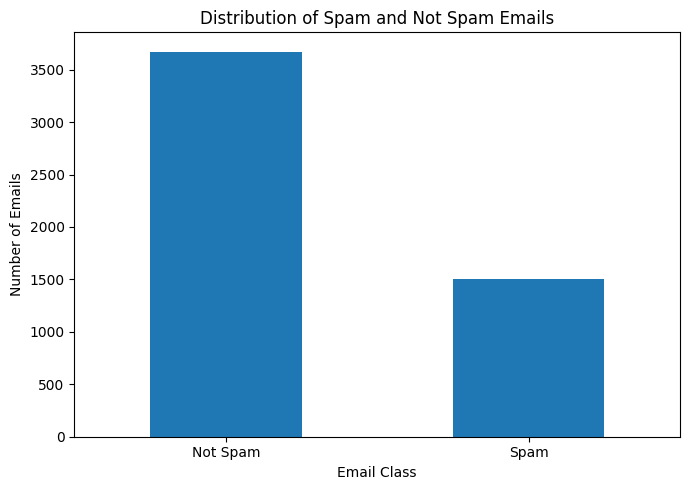

In [5]:
class_counts = y.map({
    0: "Not Spam",
    1: "Spam"
}).value_counts()

print("Class distribution:")
display(class_counts.rename("Number of Emails").to_frame())

plt.figure(figsize=(7, 5))
class_counts.plot(kind="bar")
plt.title("Distribution of Spam and Not Spam Emails")
plt.xlabel("Email Class")
plt.ylabel("Number of Emails")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

# Store results for the final comparison
results = {}
predictions = {}

# Common evaluation function
def evaluate_model(name, model):
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        )
    }

    print(f"\n{name} - Classification Report")
    print("-" * 50)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Not Spam (0)", "Spam (1)"],
            zero_division=0
        )
    )

Training features: (4137, 2999)
Testing features: (1035, 2999)

Training target distribution:
Prediction
0    2937
1    1200
Name: count, dtype: int64

Testing target distribution:
Prediction
0    735
1    300
Name: count, dtype: int64


In [7]:
# Create the KNN classifier
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    )
)

# Train the model
knn_model.fit(X_train, y_train)

# Evaluate the model
evaluate_model("KNN", knn_model)

print("KNN model training and evaluation completed.")


KNN - Classification Report
--------------------------------------------------
              precision    recall  f1-score   support

Not Spam (0)       0.98      0.80      0.88       735
    Spam (1)       0.67      0.96      0.79       300

    accuracy                           0.85      1035
   macro avg       0.82      0.88      0.84      1035
weighted avg       0.89      0.85      0.86      1035

KNN model training and evaluation completed.


In [8]:
# Create the SVM classifier
svm_model = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=20000
    )
)

# Train the model
svm_model.fit(X_train, y_train)

# Evaluate the model
evaluate_model("SVM", svm_model)

print("SVM model training and evaluation completed.")


SVM - Classification Report
--------------------------------------------------
              precision    recall  f1-score   support

Not Spam (0)       0.98      0.93      0.95       735
    Spam (1)       0.84      0.95      0.89       300

    accuracy                           0.93      1035
   macro avg       0.91      0.94      0.92      1035
weighted avg       0.94      0.93      0.94      1035

SVM model training and evaluation completed.


In [9]:
comparison = pd.DataFrame(results).T

metrics_to_compare = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

comparison = comparison[metrics_to_compare]

print("Performance Comparison of KNN and SVM")
display(comparison.style.format("{:.4f}"))

print("\nBest model based on F1-score:")
best_model = comparison["F1-score"].idxmax()

print(
    f"{best_model} with an F1-score of "
    f"{comparison.loc[best_model, 'F1-score']:.4f}"
)

Performance Comparison of KNN and SVM


,Accuracy,Precision,Recall,F1-score
KNN,0.8493,0.6659,0.9633,0.7875
SVM,0.9343,0.8412,0.9533,0.8938



Best model based on F1-score:
SVM with an F1-score of 0.8938


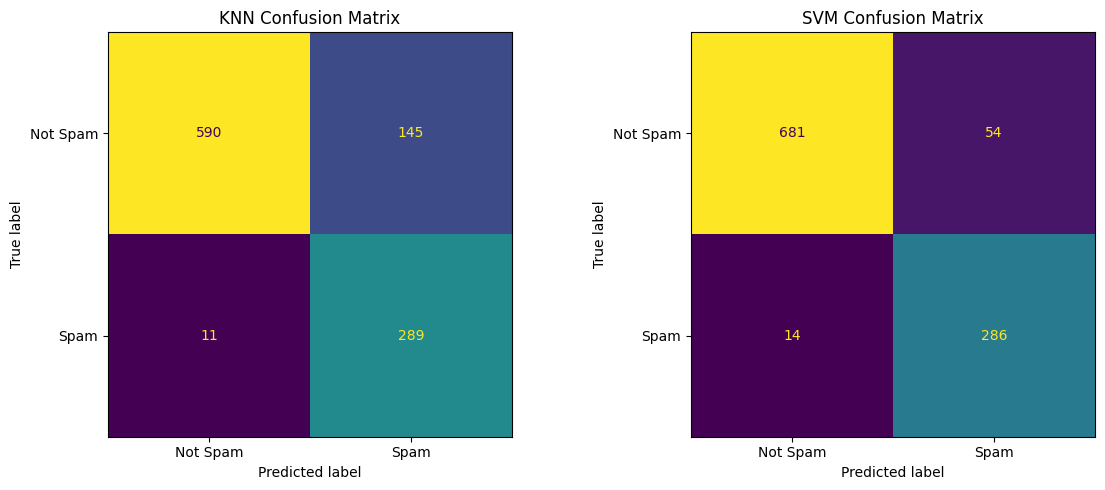

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes = np.atleast_1d(axes)

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Spam", "Spam"]
    )

    display_matrix.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{name} Confusion Matrix")

plt.tight_layout()
plt.show()

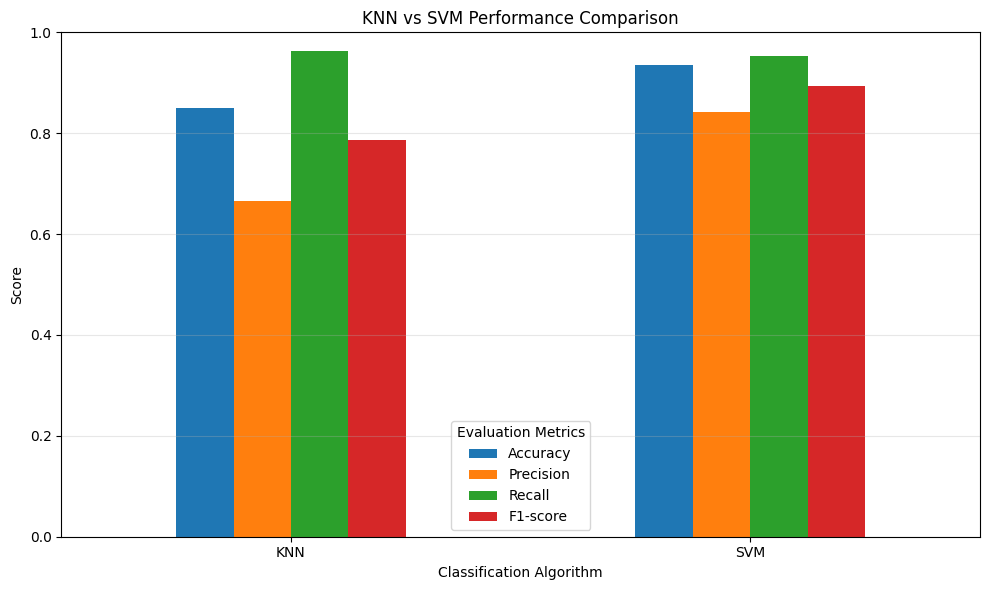

In [11]:
comparison.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1)
)

plt.title("KNN vs SVM Performance Comparison")
plt.xlabel("Classification Algorithm")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
print("=" * 60)
print("FINAL ANALYSIS AND CONCLUSION")
print("=" * 60)

best_accuracy_model = comparison["Accuracy"].idxmax()
best_f1_model = comparison["F1-score"].idxmax()
best_recall_model = comparison["Recall"].idxmax()

print(
    f"\n1. Highest Accuracy: {best_accuracy_model} "
    f"({comparison.loc[best_accuracy_model, 'Accuracy']:.4f})"
)

print(
    f"2. Highest F1-score: {best_f1_model} "
    f"({comparison.loc[best_f1_model, 'F1-score']:.4f})"
)

print(
    f"3. Highest Spam Recall: {best_recall_model} "
    f"({comparison.loc[best_recall_model, 'Recall']:.4f})"
)

print("\nInterpretation:")
print(
    "Accuracy measures the proportion of all emails classified correctly."
)
print(
    "Precision measures how many emails predicted as spam are actually spam."
)
print(
    "Recall measures how many actual spam emails the model successfully detects."
)
print(
    "The F1-score balances precision and recall."
)

print(
    f"\nConclusion: Based on the F1-score, {best_f1_model} "
    "performed best on this test set."
)

print(
    "For practical spam detection, precision and recall should also be "
    "considered, since false spam alerts and missed spam emails both matter."
)

FINAL ANALYSIS AND CONCLUSION

1. Highest Accuracy: SVM (0.9343)
2. Highest F1-score: SVM (0.8938)
3. Highest Spam Recall: KNN (0.9633)

Interpretation:
Accuracy measures the proportion of all emails classified correctly.
Precision measures how many emails predicted as spam are actually spam.
Recall measures how many actual spam emails the model successfully detects.
The F1-score balances precision and recall.

Conclusion: Based on the F1-score, SVM performed best on this test set.
For practical spam detection, precision and recall should also be considered, since false spam alerts and missed spam emails both matter.
